# LoRA — Low-Rank Adaptation

Keep trained weights; learn a small correction. **4 inputs → 5 outputs** throughout. Run the two code cells in order.

## 1. Start with learned weights

<img src="images/lora/01-base-layer.png" width="70%" alt="Four input values pass through 20 learned weights W to make five predictions. A new task needs a correction delta W.">

Full fine-tuning changes all 20 weights; LoRA keeps them fixed.

## 2. Use one correction pattern

<img src="images/lora/02-rank-one.png" width="70%" alt="A turns four input values into one number z; B turns z into five corrections. This rank-one adapter learns four plus five values.">

We assume a few correction patterns will suffice. Only the correction is constrained; W can remain full rank.

## 3. Choose capacity, then strength

<img src="images/lora/03-rank-and-scale.png" width="70%" alt="Rank r sets the maximum number of independent patterns. Alpha divided by r scales their combined correction. With r one and alpha two, add twice the raw correction.">

$\Delta W=(\alpha/r)BA$. More patterns mean more trainable values. (NOT CLEAR!)

## 4. Learn from prediction errors

<img src="images/lora/04-training.png" width="70%" alt="Full fine-tuning learns 20 update values; rank-one LoRA learns 9 factor values. The input follows frozen W and the trainable A, z, B path scaled by two. Add their predictions and use error against the target to adjust A and B. B begins at zero.">

F.linear applies a weight matrix to each input example.

In [1]:
import torch
from torch import nn
from torch.nn import functional as F

class LoRA(nn.Module):
    def __init__(self, W, r=1, alpha=2):
        super().__init__()
        self.W = nn.Parameter(W.clone(), requires_grad=False)  # frozen
        self.A = nn.Parameter(torch.randn(r, 4) * 0.1)  # nonzero so B can learn
        self.B = nn.Parameter(torch.zeros(5, r))        # zero initial correction
        self.scale = alpha / r

    def forward(self, x):
        base = F.linear(x, self.W)
        z = F.linear(x, self.A)
        return base + self.scale * F.linear(z, self.B)

## 5. Learn, check, and merge

Toy task: **+0.2 per weight** — one shared correction pattern. After training, combine the paths:

$$Wx + 2B(Ax) = (W + 2BA)x = W_{\mathrm{merged}}x.$$

20 frozen weights; 9 trainable adapter values
Initial output unchanged; base weights fixed; merged output matches.


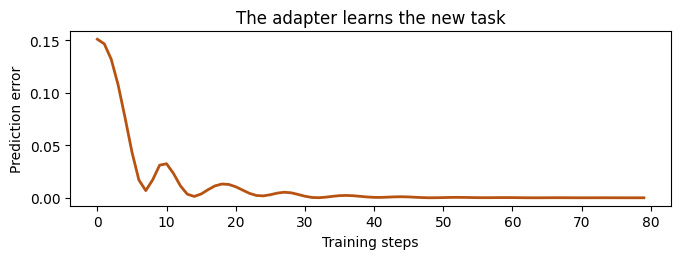

In [2]:
import matplotlib.pyplot as plt

torch.manual_seed(0)
W0 = torch.randn(5, 4)                     # toy stand-in for trained weights
x = torch.randn(64, 4)                    # 64 examples, 4 values each
target = F.linear(x, W0 + 0.2)             # new task: add 0.2 to every weight
model = LoRA(W0, r=1, alpha=2)
torch.testing.assert_close(model(x), F.linear(x, W0))  # B=0: same initial output
optimizer = torch.optim.Adam([model.A, model.B], lr=0.05)

losses = []
for _ in range(80):
    optimizer.zero_grad()
    loss = F.mse_loss(model(x), target)     # prediction error
    loss.backward()
    optimizer.step()                     # adjust only A and B
    losses.append(loss.item())

with torch.no_grad():
    merged_W = model.W + model.scale * (model.B @ model.A)
    torch.testing.assert_close(model(x), F.linear(x, merged_W))
assert torch.equal(model.W, W0)
print('20 frozen weights; 9 trainable adapter values')
print('Initial output unchanged; base weights fixed; merged output matches.')

plt.figure(figsize=(7, 2.7))
plt.plot(losses, color='#B65313', linewidth=2)
plt.xlabel('Training steps')
plt.ylabel('Prediction error')
plt.title('The adapter learns the new task')
plt.tight_layout()
plt.show()

In LLMs, repeat this adapter on selected linear layers, such as attention projections.

References: [paper](https://arxiv.org/html/2106.09685#S4.SS1) · [Umar: video](https://www.youtube.com/watch?v=PXWYUTMt-AU) / [code](https://github.com/hkproj/pytorch-lora) · [rank intuition](https://www.youtube.com/watch?v=Gy9jrVQTY4Q) · [other walkthrough](https://www.youtube.com/watch?v=rNbLfkBkolQ) · [Raschka](https://github.com/rasbt/LLMs-from-scratch/blob/main/appendix-E/01_main-chapter-code/appendix-E.ipynb).